# FRB population DM distribution - DSA-110 (coherent mode)

Same single-telescope pipeline as the Apertif / MeerKAT CB notebooks, for DSA-110:

1. DSA-110 parameters (`dsa-110`).
2. Gain = `n_dishes` x single-dish gain x **two beam attenuations**:
   - primary (dish) beam, Gaussian with `FWHM = 1.22 c / (nu D)` evaluated at the FRB's angle from the pointing centre;
   - tied-beam response (2 beams separated along x, per-frequency sigma from `DSA110_beam_parameters.csv`), evaluated at an FRB position drawn inside one beam cell (rectangle, x within +-beam_sep/2, y within +-4 sigma) and taking the max over the two beams.
3. Sky area for the volume term = pi (2 FWHM(nu_min))^2.

The last cell saves the weighted DM distribution to `/home/thsu/FRB_population/DM_distribution`.


In [1]:

from pathlib import Path
import time
import numpy as np
from astropy.cosmology import Planck18 as cosmo
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad, simps, cumtrapz  # ADD cumtrapz HERE
from scipy.optimize import curve_fit
from scipy.special import erf
import sympy as sp
from scipy.stats import gaussian_kde
import matplotlib.patches as mpatches
from astropy.cosmology import Planck18 as cosmo, z_at_value
from astropy import units as u
from scipy.interpolate import interp1d
from astropy.cosmology import FlatLambdaCDM

In [2]:
# ============================================================================
# TELESCOPE SELECTION
# ============================================================================
TELESCOPE = "dsa-110"

TELESCOPE_PARAMS = {
    "dsa-110": {
        "D": 4.65,
        "eta": 0.65,
        "Trec": 22,
        "Tsky": 3,
        "BW": 187.5e6,
        "nu_cen": 1.405e9,
        "n_comp": 6,
        "n_dishes": 48,
        "n_chan": 6144,
        "mode": "coherent",
        "description": "DSA-110 array - coherent beam",
        "tsamp":32.768e-6,
        "fov": 10,           # not used: sky area = pi (2 FWHM(nu_min))^2, see main cell
    },
}


In [3]:
alpha_intrinsic = 0  # Fixed intrinsic spectral index

In [4]:

# # EFFECT CONTROL FLAGS
# # ============================================================================
USE_COSMOLOGY = True      # Tozggle Euclidean vs cosmological universe (affects distances, volumes)
USE_SFR = True           
USE_SMEARING = True      
USE_SPECTRAL_INDEX = True 


# USE_COSMOLOGY = False
# USE_SFR = False           
# USE_SMEARING = False    
# USE_SPECTRAL_INDEX = False

USE_BEAM = True
# USE_BEAM = False

# # # Luminosity function parameters
LUMINOSITY_FUNCTION = "schechter"  
# LUMINOSITY_FUNCTION = "std" 

In [5]:
# Load selected telescope
if TELESCOPE.lower() not in TELESCOPE_PARAMS:
    raise ValueError(f"Telescope must be one of: {list(TELESCOPE_PARAMS.keys())}")

params = TELESCOPE_PARAMS[TELESCOPE.lower()]

# Physical constants
k = 1.38e-23
c = 3.0e8

# Extract telescope parameters
D = params["D"]
eta = params["eta"]
n_dishes = params["n_dishes"]

# Single-dish on-axis gain (K/Jy)
G0_single = np.pi * D*D/4 * eta/2.0/k*1e-26

G0 = np.pi * D*D/4 * eta/2.0/k*1e-26 * n_dishes

Np = 2


In [6]:
# ============================================================================
# REDSHIFT PARAMETERS
# ============================================================================
dz = 0.001
z_min = 0.01
z_max = 5.0
z_array_opt = np.arange(z_min, z_max, dz)

# Options: "schechter" or "std"

L_STAR = 1e13  # Characteristic luminosity (Jy·kpc²)
ALPHA_SCH = -1.2  # Faint-end slope
L_MIN_SCH = 1e6
L_MAX_SCH = 1e16

# L_std = 2.4e14  # Jy·kpc²
L_std = 1*1e12  # Jy·kpc²

# Simulation parameters
# theta_max = 2*1.22*c/D/nu_min # please note here
fscale = 100 * 1e-7  # FRB rate scaling factor

SNR_threshold = 8.5
t_obs = 0.001
TARGET_DETECTIONS = 10  # Target 10 detections per z-bin

# Cosmology
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

np.random.seed(42)


In [7]:
def gaussian_beam_gain(nu, G0, theta, D, c):
    """
    Gaussian beam gain with frequency dependence
    G(ν) = G₀ × exp[−θ²ν²D²×2.355²/(2×1.22²×c²)]
    """
    # Exponent coefficient
    coeff = (theta**2 * D**2 * 2.355**2) / (2 * 1.22**2 * c**2)
    return G0 * np.exp(-coeff * nu**2)

# Pre-calculate constants for speed
_COEFF_CONST = (2.355**2) / (2 * 1.22**2 * (3.0e8**2))

def gaussian_beam_gain_fast(nu_array, G0, theta, D):
    """Optimized version for the inner loop"""
    coeff = theta**2 * D**2 * _COEFF_CONST
    return G0 * np.exp(-coeff * nu_array**2)


def SNR(S,t,G,BW,Np,Trec,Tsky):
    return(S*G*np.sqrt(BW*t*Np)/(Trec+Tsky))

In [8]:
def schechter_function(L, L_star, alpha, phi_star=1.0):
    """
    Schechter luminosity function.
    
    φ(L) = φ* (L/L*)^α * exp(-L/L*)
    
    Parameters:
    -----------
    L : float or array
        Luminosity
    L_star : float
        Characteristic luminosity (knee of the function)
    alpha : float
        Faint-end slope (typically negative)
    phi_star : float
        Normalization constant (default: 1.0)
    
    Returns:
    --------
    phi : float or array
        Number density at luminosity L
    """
    x = L / L_star
    return phi_star * x**alpha * np.exp(-x)

In [9]:
def create_truncated_schechter_sampler(L_min, L_max, L_star, alpha):
    """Create sampler for Schechter function truncated between L_min and L_max"""
    L_grid = np.logspace(np.log10(L_min), np.log10(L_max), 2000)
    phi_grid = schechter_function(L_grid, L_star, alpha)
    
    # REMOVE THIS LINE:
    # from scipy.integrate import cumtrapz
    
    cdf = cumtrapz(phi_grid, L_grid, initial=0)
    cdf = cdf / cdf[-1]
    
    inv_cdf = interp1d(cdf, L_grid, kind='linear', 
                       bounds_error=False, fill_value=(L_min, L_max))
    return inv_cdf

In [10]:

# ============================================================================
# CREATE TRUNCATED SCHECHTER SAMPLER FOR EACH Z
# ============================================================================
print("Creating truncated Schechter samplers...")

def create_truncated_schechter_sampler(L_min, L_max, L_star, alpha):
    """Create sampler for Schechter function truncated between L_min and L_max"""
    L_grid = np.logspace(np.log10(L_min), np.log10(L_max), 2000)
    phi_grid = schechter_function(L_grid, L_star, alpha)
    
    from scipy.integrate import cumtrapz
    cdf = cumtrapz(phi_grid, L_grid, initial=0)
    cdf = cdf / cdf[-1]
    
    inv_cdf = interp1d(cdf, L_grid, kind='linear', 
                       bounds_error=False, fill_value=(L_min, L_max))
    return inv_cdf

sampler_cache = {}
print(f"  Done!\n")

def std_sampler(L_candle):
    """Return a fixed luminosity sampler for standard candle model"""
    def sampler(u):
        return L_candle
    return sampler

Creating truncated Schechter samplers...
  Done!



In [11]:
TEL_KEY = "dsa-110"   # telescope simulated in this notebook


In [12]:
# ============================================================================
# TIED-BEAM (COHERENT) SETUP: 2 beams separated along x, per-frequency sigma
# ============================================================================

tied_params = pd.read_csv('/home/thsu/FRB_population/DSA110_beam_parameters.csv')
tied_sigma_raw = tied_params['sigma_avg'].values.astype(float)    # arcsec, per frequency
tied_fwhm_raw  = tied_params['fwhm_avg'].values.astype(float)     # arcsec, per frequency
tied_beam_sep_arcsec = float(tied_params['beam_sep'].iloc[0])     # arcsec

tied_fwhm_center = tied_fwhm_raw[len(tied_fwhm_raw) // 2]
tied_sigma_center = tied_sigma_raw[len(tied_sigma_raw) // 2]

# Half-height of the sampling rectangle in y: +-4 sigma at the central frequency (full beam)
tied_y_half_width_arcsec = 4.0 * tied_sigma_center

# Two tied beams separated along x
tied_beam_positions = np.array([
    [-tied_beam_sep_arcsec / 2.0, 0.0],    # Beam 1 centre
    [ tied_beam_sep_arcsec / 2.0, 0.0],    # Beam 2 centre
])

_tied_freq_col = next((col for col in tied_params.columns
                       if col.lower() in ('freq', 'frequency', 'nu', 'freq_hz', 'freq_mhz', 'nu_hz', 'nu_mhz')), None)

# Frequencies the csv is given at (Hz). The simulation evaluates the gain at exactly these
# frequencies (one component per csv row, as for the FAST gain csv in the original notebook).
tied_freqs_Hz = None
if _tied_freq_col is not None:
    _f = tied_params[_tied_freq_col].values.astype(float)
    tied_freqs_Hz = np.sort(_f * 1e6 if _f.max() < 1e5 else _f)

def resample_tied_sigma(nu_target):
    """tied-beam sigma (arcsec) at frequencies nu_target (Hz).
    - csv has a frequency column -> interpolate on it;
    - same number of rows as nu_target -> use directly;
    - otherwise rows are assumed to span the band uniformly and are resampled."""
    nu_target = np.atleast_1d(nu_target).astype(float)
    if _tied_freq_col is not None:
        f = tied_params[_tied_freq_col].values.astype(float)
        if f.max() < 1e5:
            f = f * 1e6
        o = np.argsort(f)
        return np.interp(nu_target, f[o], tied_sigma_raw[o])
    if len(nu_target) == len(tied_sigma_raw):
        return tied_sigma_raw.copy()
    pos = (nu_target - nu_target.min()) / max(nu_target.max() - nu_target.min(), 1e-30)
    return np.interp(pos, np.linspace(0, 1, len(tied_sigma_raw)), tied_sigma_raw)

# ---- (3) Frequency-dependent sky temperature (K) from the same csv ----------
# Same frequency rows as the beam sigma / gain, so it is resampled exactly like sigma.
_tsky_col = next((col for col in tied_params.columns if col.lower().replace("_", "").strip() == "tsky"), None)
_has_tsky = _tsky_col is not None
tsky_raw = tied_params[_tsky_col].values.astype(float) if _has_tsky else None
if _has_tsky and not np.all(np.isfinite(tsky_raw)):
    raise ValueError("Tsky column in DSA110_beam_parameters.csv contains NaN/inf")

def resample_tsky(nu_target):
    """Tsky (K) at frequencies nu_target (Hz); same logic as resample_tied_sigma.
    Falls back to the fixed TELESCOPE_PARAMS Tsky if the csv has no 'Tsky' column."""
    nu_target = np.atleast_1d(nu_target).astype(float)
    if not _has_tsky:
        return np.full(nu_target.shape, float(TELESCOPE_PARAMS[TELESCOPE.lower()]["Tsky"]))
    if _tied_freq_col is not None:
        f = tied_params[_tied_freq_col].values.astype(float)
        if f.max() < 1e5:
            f = f * 1e6
        o = np.argsort(f)
        return np.interp(nu_target, f[o], tsky_raw[o])
    if len(nu_target) == len(tsky_raw):
        return tsky_raw.copy()
    pos = (nu_target - nu_target.min()) / max(nu_target.max() - nu_target.min(), 1e-30)
    return np.interp(pos, np.linspace(0, 1, len(tsky_raw)), tsky_raw)

print(f"Tsky column: {_tsky_col or 'NOT FOUND (using fixed Tsky)'}"
      + (f", {tsky_raw.min():.2f}-{tsky_raw.max():.2f} K ({len(tsky_raw)} rows)" if _has_tsky else ""))
print(tied_params.head())
print(f"beam_sep = {tied_beam_sep_arcsec:.2f} arcsec, sigma_avg = {tied_sigma_raw.min():.2f}-{tied_sigma_raw.max():.2f} arcsec "
      f"({len(tied_sigma_raw)} rows), fwhm (centre) = {tied_fwhm_center:.2f} arcsec, "
      f"y half-width = {tied_y_half_width_arcsec:.2f} arcsec, frequency column: {_tied_freq_col or 'none'}")

def sample_frbs_in_rectangle(n, beam_sep, y_half_width):
    """n uniform positions in x in [-beam_sep/2, beam_sep/2], y in [-y_half_width, y_half_width] (arcsec)."""
    x = np.random.uniform(-beam_sep / 2.0, beam_sep / 2.0, n)
    y = np.random.uniform(-y_half_width, y_half_width, n)
    return x, y

def get_tied_response_batch(x, y, beam_pos, sigma):
    """Max-over-beams Gaussian response, vectorised over FRBs and frequencies.
    x, y: (n,) arcsec; sigma: (n_nu,) arcsec  ->  (n, n_nu)."""
    sigma = np.atleast_1d(np.asarray(sigma, dtype=float))
    d2 = ((x[:, None] - beam_pos[None, :, 0]) ** 2
          + (y[:, None] - beam_pos[None, :, 1]) ** 2)                 # (n, n_beams)
    resp = np.exp(-0.5 * d2[:, :, None] / sigma[None, None, :] ** 2)   # (n, n_beams, n_nu)
    return resp.max(axis=1)

def sample_frbs_in_disc(n, theta_lim_rad):
    """Uniform-on-the-sky angles (radian) inside a disc of radius theta_lim_rad."""
    return theta_lim_rad * np.sqrt(np.random.random(n))


Tsky column: Tsky, 3.43-3.73 K (7 rows)
   freq_MHz    sigma_x    sigma_y  sigma_avg      fwhm_x      fwhm_y  \
0   1311.25  50.065968  50.065968  50.065968  117.896346  117.896346   
1   1342.50  48.900559  48.900559  48.900559  115.152017  115.152017   
2   1373.75  47.788172  47.788172  47.788172  112.532545  112.532545   
3   1405.00  46.725268  46.725268  46.725268  110.029597  110.029597   
4   1436.25  45.708617  45.708617  45.708617  107.635567  107.635567   

     fwhm_avg  beam_sep      Tsky  
0  117.896346      60.0  3.733172  
1  115.152017      60.0  3.671802  
2  112.532545      60.0  3.615366  
3  110.029597      60.0  3.563369  
4  107.635567      60.0  3.515374  
beam_sep = 60.00 arcsec, sigma_avg = 43.80-50.07 arcsec (7 rows), fwhm (centre) = 110.03 arcsec, y half-width = 186.90 arcsec, frequency column: freq_MHz


In [13]:
# ============================================================================
# SINGLE-TELESCOPE DM POPULATION + FLUENCE-vs-DM, SINGLE PASS  (DSA-110 coherent mode)
# ============================================================================
# Gain model per FRB and frequency:
#     G(nu) = n_dishes * G0_single * primary_envelope(theta_frb, nu) * tied_beam_response(x, y, nu)
# primary_envelope = exp(-(C theta^2) nu^2), C = D^2 2.355^2 / (2 1.22^2 c^2)   [dish Gaussian beam]
# Sky area = pi (2 FWHM(nu_min))^2 and FRB angles are drawn over that disc (as in the IB notebook).

print("\n" + "="*100)
print("RUNNING SINGLE-TELESCOPE RUN (DSA-110 coherent mode)")
print("="*100 + "\n")

all_results = {}
fluence_dm_results = {}
population_totals = {}

colors_tel = {"dsa-110": "#2ca02c"}
labels_tel = {"dsa-110": "DSA-110"}

H0_km_s_Mpc = cosmo.H0.value if hasattr(cosmo, "H0") else 70.0
DH_Mpc = 299792.458 / H0_km_s_Mpc

# Schechter CDF interpolator -- built ONCE
_L_grid_full = np.logspace(np.log10(L_MIN_SCH), np.log10(L_MAX_SCH), 5000)
_phi_grid_full = schechter_function(_L_grid_full, L_STAR, ALPHA_SCH)
_cdf_full = cumtrapz(_phi_grid_full, _L_grid_full, initial=0)
_cdf_full /= _cdf_full[-1]
_cdf_interp = interp1d(_L_grid_full, _cdf_full, kind="linear",
                       bounds_error=False, fill_value=(0.0, 1.0))

def n_ratio_for(L_min_z):
    if LUMINOSITY_FUNCTION.lower() == "std":
        return 1.0 if L_std >= L_min_z else 0.0
    return 1.0 - _cdf_interp(L_min_z)

BATCH_SIZE = 4096

for tel_key in [TEL_KEY]:
    print(f"\n{'='*60}\nTELESCOPE: {labels_tel[tel_key]}\n{'='*60}")

    params = TELESCOPE_PARAMS[tel_key]
    D = params["D"]
    n_dishes = params["n_dishes"]

    np.random.seed(42)

    L_min_by_z_new = {}
    nu0 = params["nu_cen"]
    nu_cen = params["nu_cen"]
    Trec = params["Trec"]
    BW = params["BW"]
    n_comp = params["n_comp"]
    BW_comp = BW / n_comp
    nu_min = nu0 - BW / 2
    nu_max = nu0 + BW / 2
    n_chan = params["n_chan"]
    BW_chan = BW / n_chan
    if tied_freqs_Hz is not None:
        # evaluate at exactly the csv frequencies: one frequency component per csv row
        nu_array = tied_freqs_Hz.copy()
        if len(nu_array) != n_comp:
            print(f"  NOTE: n_comp {n_comp} -> {len(nu_array)} to match the csv rows")
        n_comp = len(nu_array)
        BW_comp = BW / n_comp
    else:
        # no frequency column: csv rows are taken to span the band uniformly, one component per row
        nu_array = np.linspace(nu_min, nu_max, len(tied_sigma_raw))
        n_comp = len(nu_array)
        BW_comp = BW / n_comp
    freq_powers_scatter = (nu_array / 1e9) ** (-4)

    # Sky area = disc of radius 2 x FWHM at nu_min; FRB angles are drawn over the whole disc
    fwhm_rad = 1.22 * (c / nu_min) / D
    fwhm_deg = fwhm_rad * (180 / np.pi)
    r_deg = 2.0 * fwhm_deg
    area_tel = np.pi * r_deg ** 2
    theta_max = 2.0 * fwhm_rad
    theta_draw = theta_max
    f_area = 1.0
    _INNER_COEFF_CONST_new = (D ** 2 * 2.355 ** 2) / (2 * 1.22 ** 2 * c ** 2)
    tied_sigma_nu = resample_tied_sigma(nu_array)                    # arcsec, per frequency
    tied_sigma_0 = resample_tied_sigma(np.array([nu0]))              # arcsec, at nu0
    Tsky_nu = resample_tsky(nu_array)                                # K, per frequency (from csv)
    Tsky_0 = float(resample_tsky(np.array([nu0]))[0])                # K, at nu0

    # Coherent gain: n_dishes x single-dish gain (primary-beam part)
    G0_single = np.pi * D * D / 4 * params["eta"] / 2.0 / k * 1e-26
    G0 = n_dishes * G0_single
    G0_max = G0   # best case: on a tied-beam centre, on the primary-beam axis
    G0_desc = f"{G0:.4e} K/Jy ({n_dishes} x {G0_single:.4e})"

    print(f"  Diameter: {D} m, G0: {G0_desc}")
    print(f"  Primary FWHM at nu_min: {fwhm_deg:.3f} deg, disc radius {r_deg:.3f} deg")
    print(f"  n_comp: {n_comp}, nu_array: {nu_array[0]/1e6:.0f}-{nu_array[-1]/1e6:.0f} MHz ({len(nu_array)} points)")
    print(f"  Sky area: {area_tel:.4f} deg\u00b2")
    print(f"  Trec: {Trec} K, Tsky: {Tsky_nu.min():.1f}-{Tsky_nu.max():.1f} K ({Tsky_0:.1f} K at nu0), BW: {BW/1e6:.0f} MHz, nu_cen: {nu_cen/1e9:.3f} GHz")

    for z in z_array_opt:
        dl = (cosmo.luminosity_distance(z).value * 1000.0) if USE_COSMOLOGY else (DH_Mpc * z * 1000.0)
        G_max = gaussian_beam_gain(nu0, G0_max, 0, D, 3.0e8)
        S_min = SNR_threshold * (Trec + Tsky_0) / (G_max * np.sqrt(BW * t_obs * Np))
        z_factor = (1 + z) ** (-1 - alpha_intrinsic) if USE_SPECTRAL_INDEX else 1.0
        L_min = S_min * (dl ** 2) * z_factor
        L_min_by_z_new[z] = np.clip(L_min, L_MIN_SCH, L_MAX_SCH)

    sampler_cache.clear()

    results_tel = []
    tel_events = []

    # S_SNR_CONST = np.sqrt(BW_comp * t_obs * Np) / (Trec + Tsky_nu)   # (n_nu,) per-frequency noise
    nu_scaling = (nu_array / nu0) ** alpha_intrinsic if USE_SPECTRAL_INDEX else np.ones_like(nu_array)

    for z_idx, z in enumerate(z_array_opt):
        zmin, zmax = z - 0.5 * dz, z + 0.5 * dz
        L_min_z = L_min_by_z_new[z]

        if LUMINOSITY_FUNCTION.lower() == "std":
            if L_min_z > L_std:
                break
            truncated_sampler = std_sampler(L_std)
        else:
            # if L_min_z > 8.952e15:
            #     break
            if L_min_z not in sampler_cache:
                sampler_cache[L_min_z] = create_truncated_schechter_sampler(
                    L_min_z, L_MAX_SCH, L_STAR, ALPHA_SCH
                )
            truncated_sampler = sampler_cache[L_min_z]

        DM = 1000 * z
        wi_z = 0.001 * (1 + z)
        BW_chan_MHz = BW_chan / 1e6
        nu_cen_GHz = nu_cen / 1e9

        if USE_SMEARING:
            w_DM = 8.3e-6 * DM * BW_chan_MHz / (nu_cen_GHz ** 3)
            # w_scatter_comp = (
            #     1.9e-7 * (DM ** 1.5) * (1 + (DM ** 3) * 3.55e-5) * 3 * freq_powers_scatter * 1e-3
            # )
            # w_scatter = np.sqrt(np.sum(w_scatter_comp ** 2) / len(w_scatter_comp))
            w_scatter = 0
            w_sampling = params["tsamp"]
        else:
            w_DM = w_scatter = w_sampling = 0.0

        w_obs_factor = np.sqrt(wi_z ** 2 + w_DM ** 2 + w_scatter ** 2 + w_sampling ** 2)
        S_SNR_CONST = np.sqrt(BW_comp * w_obs_factor * Np) / (Trec + Tsky_nu)
        dl = (cosmo.luminosity_distance(z).value * 1000.0) if USE_COSMOLOGY else (DH_Mpc * z * 1000.0)
        z_factor = (1 + z) ** (-1 - alpha_intrinsic) if USE_SPECTRAL_INDEX else 1.0

        n_generated = 0
        detected = []
        max_iterations = 10000

        while len(detected) < TARGET_DETECTIONS and n_generated < max_iterations:
            n = min(BATCH_SIZE, max_iterations - n_generated)

            # 1. Angle from the pointing centre (primary beam)
            theta_frb = sample_frbs_in_disc(n, theta_draw)

            # 2. Position inside one tied-beam cell (tied-beam response)
            frb_x, frb_y = sample_frbs_in_rectangle(n, tied_beam_sep_arcsec, tied_y_half_width_arcsec)

            # 3. Luminosity / flux
            lum_b = np.asarray(truncated_sampler(np.random.uniform(0, 1, n)), dtype=float)
            if LUMINOSITY_FUNCTION.lower() == "std":
                lum_b = np.full(n, L_std, dtype=float)
            S0_b = (lum_b / (dl ** 2 * z_factor)) * (wi_z / w_obs_factor)
            S_nu_b = S0_b[:, None] * nu_scaling[None, :]

            # 4. Gain = n_dishes*G0_single * primary envelope * tied-beam response
            if USE_BEAM:
                primary_envelope = np.exp(-(_INNER_COEFF_CONST_new * theta_frb[:, None] ** 2) * nu_array[None, :] ** 2)
                beam_responses = get_tied_response_batch(frb_x, frb_y, tied_beam_positions, tied_sigma_nu)
                G_nu_b = G0 * primary_envelope * beam_responses
                # gain ratio at nu0, G/G0 <= 1
                prim0 = np.exp(-_INNER_COEFF_CONST_new * theta_frb ** 2 * nu0 ** 2)
                tied0 = get_tied_response_batch(frb_x, frb_y, tied_beam_positions, tied_sigma_0)[:, 0]
                gain_ratio_b = prim0 * tied0
            else:
                G_nu_b = G0 * np.ones((n, len(nu_array)))
                gain_ratio_b = np.ones(n)

            # 5. S/N
            snr_spectrum_b = S_nu_b * G_nu_b * S_SNR_CONST
            snr_coherent_b = snr_spectrum_b.sum(axis=1) / np.sqrt(n_comp)

            hits = np.where(snr_coherent_b > SNR_threshold)[0]

            need = TARGET_DETECTIONS - len(detected)
            if len(hits) >= need:
                hits_used = hits[:need]
                n_generated += int(hits_used[-1]) + 1
            else:
                hits_used = hits
                n_generated += n

            for i in hits_used:
                fluence_Jyms = (lum_b[i] / (dl ** 2 * z_factor)) * (wi_z * 1000.0)
                detected.append((lum_b[i], fluence_Jyms, gain_ratio_b[i], snr_coherent_b[i]))

        n_detected = len(detected)

        if n_detected == TARGET_DETECTIONS:
            detection_rate = (n_detected / n_generated) * f_area   # x fraction of the fov covered by the draw disc
            N_ratio = n_ratio_for(L_min_z)

            if USE_COSMOLOGY:
                dt = (cosmo.age(zmin).value - cosmo.age(zmax).value) * 1e9
                dvol = (
                    cosmo.comoving_volume(zmax).value - cosmo.comoving_volume(zmin).value
                ) * (area_tel / (4.0 * np.pi * ((180.0 / np.pi) ** 2)))
            else:
                r_Mpc = DH_Mpc * z
                dr_Mpc = DH_Mpc * dz
                area_sr = area_tel * (np.pi / 180.0) ** 2
                dvol = (r_Mpc ** 2) * dr_Mpc * area_sr
                dr_m = dr_Mpc * 3.0857e22
                dt = dr_m / c / (3600.0 * 24.0 * 365.0)

            psi = (0.015 * ((1 + z) ** 2.7) / (1 + ((1 + z) / 2.9) ** 5.6)) if USE_SFR else 0.015
            nfrb_sfr = psi * dvol * dt * fscale
            n_total_population = detection_rate * N_ratio * nfrb_sfr

            results_tel.append({"z": z, "DM": DM, "n_total_population": n_total_population})

            weight_per_event = n_total_population / TARGET_DETECTIONS
            for lum, fluence_Jyms, gain_ratio, snr_det in detected:
                tel_events.append({
                    "DM": DM, "z": z, "fluence": fluence_Jyms, "weight": weight_per_event,
                    "lum_true": lum, "gain_ratio": gain_ratio,
                    "fluence_obs": fluence_Jyms * gain_ratio,
                    "lum_inferred": lum * gain_ratio,
                    "snr": snr_det,
                })

            if z_idx % 50 == 0:
                print(f"  z={z:.2f}: Pop {n_total_population:.1f}")

    if len(results_tel) == 0:
        raise RuntimeError("No redshift bin reached TARGET_DETECTIONS. Check the tied-beam geometry "
                           "(DSA110_beam_parameters.csv, tied_y_half_width_arcsec) and the primary-beam printout above.")
    n_frb_weighted = sum(e["weight"] for e in tel_events)
    print(f"  \u2713 {len(results_tel)} redshift bins, {len(tel_events)} detected-FRB samples "
          f"-> n_frb (weighted) = {n_frb_weighted:.1f}")

    all_results[tel_key] = results_tel
    fluence_dm_results[tel_key] = tel_events
    population_totals[tel_key] = np.array([e["weight"] for e in tel_events])

print(f"\n{'='*100}")
print("DONE")
print(f"{'='*100}\n")



RUNNING SINGLE-TELESCOPE RUN (DSA-110 coherent mode)


TELESCOPE: DSA-110
  NOTE: n_comp 6 -> 7 to match the csv rows
  Diameter: 4.65 m, G0: 1.9197e-01 K/Jy (48 x 3.9994e-03)
  Primary FWHM at nu_min: 3.439 deg, disc radius 6.879 deg
  n_comp: 7, nu_array: 1311-1499 MHz (7 points)
  Sky area: 148.6416 deg²
  Trec: 22 K, Tsky: 3.4-3.7 K (3.6 K at nu0), BW: 188 MHz, nu_cen: 1.405 GHz
  z=0.01: Pop 17.5
  z=0.06: Pop 84.9
  z=0.11: Pop 130.0
  z=0.16: Pop 98.9
  z=0.21: Pop 87.6
  z=0.26: Pop 69.7
  z=0.31: Pop 57.2
  z=0.36: Pop 42.6
  z=0.41: Pop 85.1
  z=0.46: Pop 31.0
  z=0.51: Pop 19.3
  z=0.56: Pop 16.7
  z=0.61: Pop 11.8
  z=0.66: Pop 9.4
  z=0.71: Pop 6.0
  z=0.76: Pop 3.7
  z=0.81: Pop 1.9
  z=0.86: Pop 1.2
  z=0.91: Pop 1.3
  z=0.96: Pop 1.5
  z=1.01: Pop 0.9
  z=1.06: Pop 0.3
  z=1.11: Pop 0.3
  z=1.16: Pop 0.1
  z=1.21: Pop 0.1
  z=1.26: Pop 0.0
  z=1.31: Pop 0.0
  z=1.36: Pop 0.0
  z=1.41: Pop 0.0
  z=1.46: Pop 0.0
  z=1.51: Pop 0.0
  z=1.56: Pop 0.0
  z=1.61: Pop 0.0
  z=1

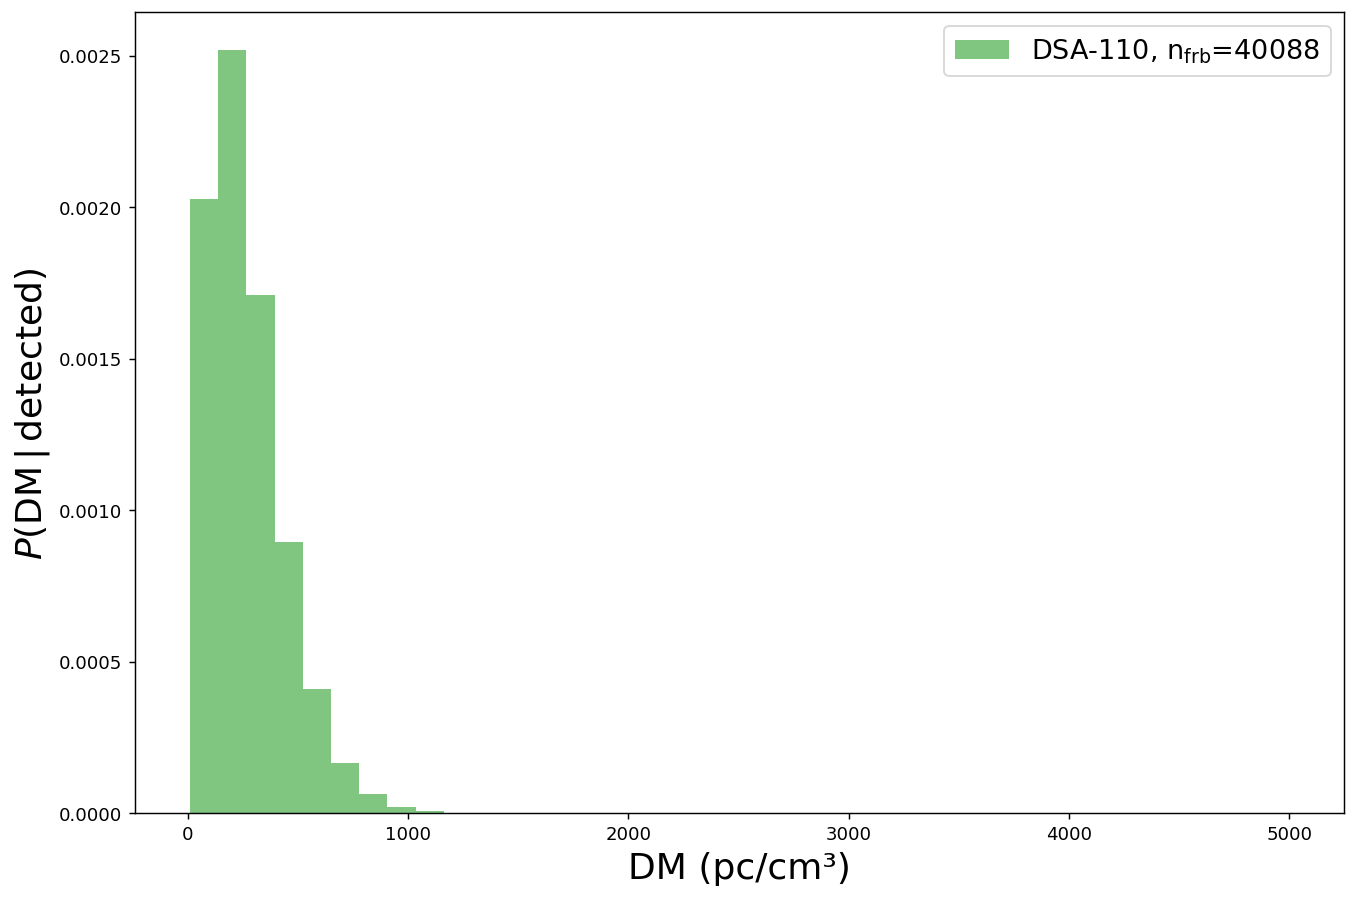

In [14]:
%matplotlib inline
# ----------------------------------------------------------------------------
# DM histogram (weighted population) for this telescope
# ----------------------------------------------------------------------------
results = all_results[TEL_KEY]
DMs  = np.array([r["DM"] for r in results])
pops = np.array([r["n_total_population"] for r in results])
nfrb = pops.sum()

fig, ax = plt.subplots(figsize=(12, 8), dpi=130)
bins = np.linspace(DMs.min(), DMs.max(), 40)
ax.hist(DMs, bins=bins, weights=pops, density=True, alpha=0.6, color=colors_tel[TEL_KEY],
        label=f'{labels_tel[TEL_KEY]}, n$_{{\\mathrm{{frb}}}}$={int(nfrb)}')
ax.set_xlabel("DM (pc/cm\u00b3)", fontsize=20)
ax.set_ylabel(r"$P(\mathrm{DM}\,|\,\mathrm{detected})$", fontsize=20)
ax.legend(fontsize=15)
plt.show()


In [15]:
# ----------------------------------------------------------------------------
# SAVE: DM distribution of the weighted population -> .npy
#
# Array shape (N, 2), one row per redshift bin that had detections:
#   column 0 = DM (pc/cm^3)          (= 1000 * z)
#   column 1 = n_total_population    (weighted number of FRBs in that bin)
# Weighted DM histogram: np.histogram(arr[:,0], bins=..., weights=arr[:,1]).
# ----------------------------------------------------------------------------
import os
OUT_DIR = "/home/thsu/FRB_population/DM_distribution"
os.makedirs(OUT_DIR, exist_ok=True)

dm_distribution = np.column_stack([DMs, pops])
out_path = os.path.join(OUT_DIR, "DM_distribution_dsa110.npy")
np.save(out_path, dm_distribution)
print(f"Saved {dm_distribution.shape} array (DM, weighted population) -> {out_path}")
print(f"Total weighted population: {pops.sum():.1f}")


Saved (4990, 2) array (DM, weighted population) -> /home/thsu/FRB_population/DM_distribution/DM_distribution_dsa110.npy
Total weighted population: 40088.3
